# TP1 — Parte II | EPH 2026-T1


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from os.path import join
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

AZUL = "#0F285A"
DORADO = "#AA8448"
GRIS_AZUL = "#607896"


In [ ]:
# Buscar TP_01 desde el directorio actual o desde alguna de sus carpetas superiores
# (igual que en las Partes I y III: funciona si VS Code abre el notebook desde C_Programs o desde TP_01).
carpetas = [Path.cwd(), *Path.cwd().parents]
candidatas = carpetas + [p / "TP_01" for p in carpetas]
main_path = next(
    (p for p in candidatas if (p / "B_Outputs" / "B_Data" / "EPH_T126_limpia.csv").is_file()),
    None
)
if main_path is None:
    raise FileNotFoundError("No se encontró TP_01/B_Outputs/B_Data/EPH_T126_limpia.csv. "
                            "Abrir el repositorio en VS Code.")

# Carpetas del proyecto
a_path = join(main_path, "A_Inputs")
b_path = join(main_path, "B_Outputs")
c_path = join(main_path, "C_Programs")

# Carpetas secundarias
b_path_data = join(b_path, "B_Data")
b_path_figr = join(b_path, "B_Figure")
b_path_tabl = join(b_path, "B_Table")


## Lectura de la base limpia
Usamos la partición de la Parte I (columna `conjunto`); no se vuelve a dividir.

In [ ]:
base = pd.read_csv(join(b_path_data, "EPH_T126_limpia.csv"))

train = base.loc[base["conjunto"] == "train"]
test = base.loc[base["conjunto"] == "test"]

X_train = train.drop(columns=["informal", "conjunto"])     # incluye la columna const
X_test = test.drop(columns=["informal", "conjunto"])
y_train = train["informal"].astype(int)
y_test = test["informal"].astype(int)

assert X_train.columns.equals(X_test.columns) and X_train.columns[0] == "const"
assert X_train.shape == (13692, 69) and X_test.shape == (5868, 69)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"informalidad en entrenamiento: {y_train.mean():.2%}   en testeo: {y_test.mean():.2%}")

X_train: (13692, 69) | X_test: (5868, 69)
informalidad en entrenamiento: 45.60%   en testeo: 43.52%


## Inciso 5. Regresión logística
Estimamos regresión logística con `X_train`.

In [ ]:
# Inciso 5: regresión logística 
logit = sm.Logit(y_train, X_train).fit(disp=0)
print("Convergió:", logit.mle_retvals["converged"], "| iteraciones:", logit.mle_retvals["iterations"])

# Inciso 5: tabla con (i) coeficientes, (ii) errores estándar y (iii) odds ratios
tabla_logit = pd.DataFrame({
    "coeficiente": logit.params,
    "error estándar": logit.bse,
    "odds ratio": np.exp(logit.params),
})
tabla_logit.round(4)

Convergió: True | iteraciones: 7


,coeficiente,error estándar,odds ratio
const,9.1544,0.4767,9456.1381
CH06,-0.1502,0.0115,0.8605
edad2,0.0014,0.0001,1.0014
nhogar,0.0703,0.0192,1.0728
prop_ocupados,-0.1750,0.1083,0.8395
...,...,...,...
II7_5.0,-1.2208,0.5013,0.2950
II7_6.0,0.2977,0.1030,1.3467
II7_7.0,0.6153,0.3900,1.8503
II7_8.0,0.5939,0.2060,1.8110


In [ ]:
# Inciso 5: exportamos la tabla completa con los coeficientes pedidos.
tabla_logit.to_csv(join(b_path_tabl, "tabla_logit_completa.csv"), encoding="utf-8-sig")
print("Coeficientes exportados:", len(tabla_logit))

Coeficientes exportados: 69


In [ ]:
# Inciso 5: coeficiente, error estándar y odds ratio de las variables a interpretar.
# El odds ratio multiplica el odds p/(1-p); no multiplica la probabilidad.
b, ee = logit.params, logit.bse
for v in ["NIVEL_ED_6", "log_ingreso"]:
    print(f"{v}: coeficiente = {b[v]:.3f} | error estándar = {ee[v]:.3f} | odds ratio = {np.exp(b[v]):.3f}")

# NIVEL_ED_6 es una indicadora: su odds ratio compara contra la categoría omitida (primario incompleto).
print(f"Odds de ser informal con universitario completo vs. primario incompleto: {1 - np.exp(b['NIVEL_ED_6']):.1%} menor")

# La edad entra en nivel y al cuadrado: el efecto no es lineal y el signo de cada coeficiente por separado no alcanza.
edad_pico = -b["CH06"] / (2 * b["edad2"])
print(f"CH06 = {b['CH06']:.4f} y edad2 = {b['edad2']:.5f}: el logit de informalidad tiene su mínimo en {edad_pico:.1f} años")

NIVEL_ED_6: coeficiente = -2.007 | error estándar = 0.165 | odds ratio = 0.134
log_ingreso: coeficiente = -0.316 | error estándar = 0.024 | odds ratio = 0.729
Odds de ser informal con universitario completo vs. primario incompleto: 86.6% menor
CH06 = -0.1502 y edad2 = 0.00141: el logit de informalidad tiene su mínimo en 53.4 años


# Inciso 6. Probabilidad estimada de informalidad según el ingreso
Usamos un logit con un solo predictor (`log_ingreso`) para poder dibujar la curva, como en el Tutorial 3.

const          15.4801
log_ingreso    -1.1634
dtype: float64


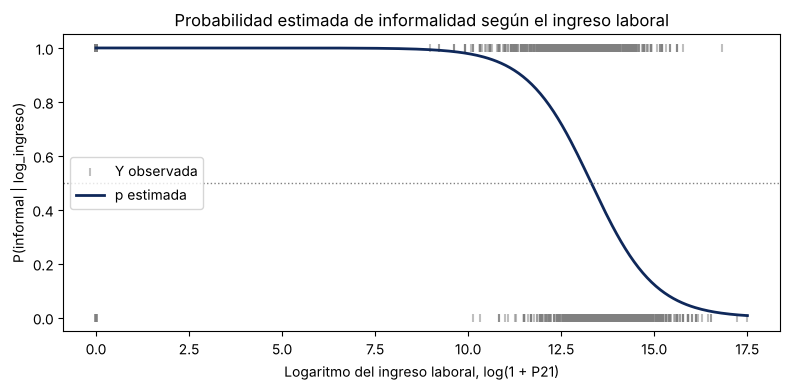

se predice informalidad con un log-ingreso menor a 13.31 (ingreso laboral menor a 600,423)
las dos reglas clasifican igual: True


In [ ]:
# Inciso 6: regresión logística con un solo predictor (log_ingreso), para poder dibujar la curva
logit_ingreso = sm.Logit(y_train, X_train[["const", "log_ingreso"]]).fit(disp=0)
print(logit_ingreso.params.round(4))

# Inciso 6: curva de P(informal = 1 | log_ingreso) sobre una grilla de valores del log-ingreso
grilla = np.linspace(0, X_train["log_ingreso"].max(), 300)
p_grilla = logit_ingreso.predict(sm.add_constant(grilla))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_train["log_ingreso"], y_train, marker="|", color="gray", alpha=0.5, label="Y observada")
ax.plot(grilla, p_grilla, color=AZUL, linewidth=2, label="p estimada")
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)

ax.set_title("Probabilidad estimada de informalidad según el ingreso laboral")
ax.set_xlabel("Logaritmo del ingreso laboral, log(1 + P21)")
ax.set_ylabel("P(informal | log_ingreso)")
ax.legend(loc="center left")
fig.tight_layout()
fig.savefig(join(b_path_figr, "prob_informal_ingreso.png"), dpi=200, bbox_inches="tight")
plt.show()

# Inciso 6: con p > 0,5 se predice informal; con pendiente negativa eso equivale a un log-ingreso menor que un corte
b1, b2 = logit_ingreso.params
corte = -b1 / b2
print(f"se predice informalidad con un log-ingreso menor a {corte:.2f} (ingreso laboral menor a {np.expm1(corte):,.0f})")
p_train = logit_ingreso.predict(X_train[["const", "log_ingreso"]])
print("las dos reglas clasifican igual:", ((p_train > 0.5) == (X_train["log_ingreso"] < corte)).all())

## Inciso 7. Análisis discriminante lineal (LDA)
Estimamos modelo de análisis discriminante usando `X_train`.

In [ ]:
# Inciso 7: LDA sobre X_train sin la constante
X_train_lda = X_train.drop(columns="const")
X_test_lda = X_test.drop(columns="const")

lda = LinearDiscriminantAnalysis().fit(X_train_lda, y_train)
print("kappa estimado (priors_) [formal, informal]:", lda.priors_.round(4))

medias = pd.DataFrame(lda.means_, columns=X_train_lda.columns, index=["formal", "informal"]).T
medias["diferencia"] = medias["informal"] - medias["formal"]
medias.to_csv(join(b_path_tabl, "tabla_lda_medias.csv"), encoding="utf-8-sig")
medias.loc[["CH06", "nhogar", "prop_ocupados", "log_ingreso", "NIVEL_ED_6"]].round(3)

kappa estimado (priors_) [formal, informal]: [0.544 0.456]


,formal,informal,diferencia
CH06,43.365,39.184,-4.181
nhogar,3.331,3.897,0.566
prop_ocupados,0.646,0.626,-0.020
log_ingreso,13.746,12.614,-1.133
NIVEL_ED_6,0.359,0.093,-0.266


In [ ]:
# Inciso 7: cuánto coincide LDA con el logit (umbral 0,5, muestra de testeo)
p_logit = logit.predict(X_test)
y_hat_logit = (p_logit > 0.5).astype(int)
y_hat_lda = lda.predict(X_test_lda)
print(f"logit y LDA clasifican igual al {(y_hat_logit == y_hat_lda).mean():.1%} de los trabajadores del testeo")

logit y LDA clasifican igual al 96.9% de los trabajadores del testeo


## Supuesto de normalidad de X dado Y

In [ ]:
# Inciso 7: ¿cuántas columnas de X son indicadoras (0/1)? Una indicadora no puede ser normal.
es_binaria = X_train_lda.apply(lambda c: set(c.unique()) <= {0.0, 1.0})
print(f"Columnas de X: {X_train_lda.shape[1]} | indicadoras: {int(es_binaria.sum())} "
      f"({es_binaria.mean():.0%}) | numéricas: {int((~es_binaria).sum())}")
print("Numéricas:", list(X_train_lda.columns[~es_binaria]))

# Inciso 7: asimetría y curtosis de las numéricas dentro de cada clase (una normal tiene 0 y 0)
numericas = list(X_train_lda.columns[~es_binaria])
filas = []
for v in numericas:
    for clase, nombre in [(0, "formal"), (1, "informal")]:
        x = X_train_lda.loc[y_train == clase, v]
        filas.append({"variable": v, "clase": nombre,
                      "asimetria": stats.skew(x), "curtosis_exceso": stats.kurtosis(x)})
normalidad = pd.DataFrame(filas)
normalidad.to_csv(join(b_path_tabl, "tabla_lda_normalidad.csv"), index=False, encoding="utf-8-sig")
normalidad.round(2)

Columnas de X: 68 | indicadoras: 62 (91%) | numéricas: 6
Numéricas: ['CH06', 'edad2', 'nhogar', 'prop_ocupados', 'log_ingreso', 'IX_MEN10']


,variable,clase,asimetria,curtosis_exceso
0,CH06,formal,0.17,-0.55
1,CH06,informal,0.51,-0.57
2,edad2,formal,0.76,0.43
3,edad2,informal,1.12,0.82
4,nhogar,formal,1.09,3.70
5,nhogar,informal,1.44,4.46
6,prop_ocupados,formal,0.16,-1.26
7,prop_ocupados,informal,0.20,-1.15
8,log_ingreso,formal,-8.59,91.13
9,log_ingreso,informal,-4.31,18.47
